In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Locate the CSV inside ../data (when notebook is in notebooks/) or ./data (if run from root)
candidate_dirs = ["../data", "data"]
csv_path = None

for folder in candidate_dirs:
    if os.path.isdir(folder):
        csv_files = [f for f in os.listdir(folder) if f.lower().endswith(".csv")]
        if csv_files:
            # Prefer a file with 'penguin' in its name if multiple CSVs exist
            preferred = [f for f in csv_files if "penguin" in f.lower()]
            chosen_file = preferred[0] if preferred else csv_files[0]
            csv_path = os.path.join(folder, chosen_file)
            break

if csv_path is None:
    raise FileNotFoundError("No CSV file found in '../data' or 'data'. Place the dataset CSV in the 'data' folder.")

print(f"Loaded file: {csv_path}")
df = pd.read_csv(csv_path)

print("\n--- First 5 Records ---")
print(df.head().to_string())

print("\n--- Last 5 Records ---")
print(df.tail().to_string())

print(f"\nDataset Shape: {df.shape[0]} rows and {df.shape[1]} columns")

print("\n--- Column Names & Data Types ---")
print(df.dtypes)

print("\n--- Numerical Summary Statistics ---")
print(df.describe().to_string())

print("\n--- Categorical Summary Statistics ---")
print(df.describe(include="object").to_string())

Loaded file: ../data\penguins.csv

--- First 5 Records ---
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g     sex  year
0  Adelie  Torgersen            39.1           18.7              181.0       3750.0    male  2007
1  Adelie  Torgersen            39.5           17.4              186.0       3800.0  female  2007
2  Adelie  Torgersen            40.3           18.0              195.0       3250.0  female  2007
3  Adelie  Torgersen             NaN            NaN                NaN          NaN     NaN  2007
4  Adelie  Torgersen            36.7           19.3              193.0       3450.0  female  2007

--- Last 5 Records ---
       species island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g     sex  year
339  Chinstrap  Dream            55.8           19.8              207.0       4000.0    male  2009
340  Chinstrap  Dream            43.5           18.1              202.0       3400.0  female  2009
341  Chinstrap  Dream           

C:\Users\manah\AppData\Local\Temp\ipykernel_2876\1371652364.py:44: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include="object").to_string())


The Palmer Penguins dataset provides physical measurements and categorical attributes for penguins across 
multiple species and islands. Numerical features capture continuous measurements such as bill dimensions, 
flipper length, and body mass, while categorical columns store discrete labels like species, island, and sex.
Comparing non-null counts across columns immediately highlights missing values in certain fields, giving a clear 
starting point for data cleaning before modeling.

--- Missing Values Report (Before Cleaning) ---
                   Missing Count  Missing (%)
species                        0         0.00
island                         0         0.00
bill_length_mm                 2         0.58
bill_depth_mm                  2         0.58
flipper_length_mm              2         0.58
body_mass_g                    2         0.58
sex                           11         3.20
year                           0         0.00


C:\Users\manah\AppData\Local\Temp\ipykernel_2876\2041316621.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=before_report.index, y=before_report["Missing Count"], palette="viridis")


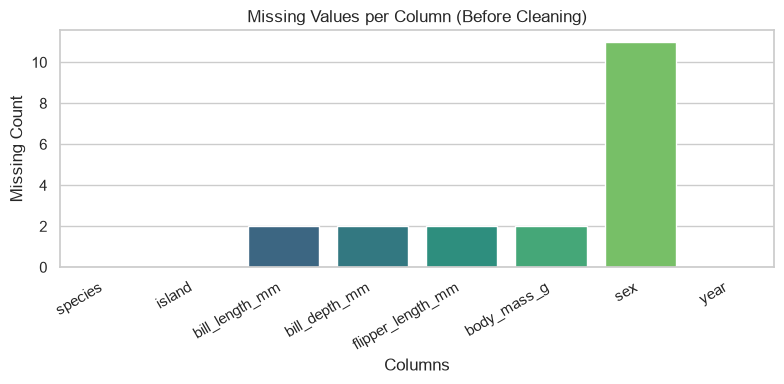


--- Missing Values Report (After Cleaning) ---
                   Missing Count  Missing (%)
species                        0          0.0
island                         0          0.0
bill_length_mm                 0          0.0
bill_depth_mm                  0          0.0
flipper_length_mm              0          0.0
body_mass_g                    0          0.0
sex                            0          0.0
year                           0          0.0


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

missing_before = df.isnull().sum()
missing_pct_before = (df.isnull().sum() / len(df)) * 100

before_report = pd.DataFrame({
    "Missing Count": missing_before,
    "Missing (%)": missing_pct_before.round(2)
})
print("--- Missing Values Report (Before Cleaning) ---")
print(before_report.to_string())

# 2. Visualize missing values
plt.figure(figsize=(8, 4))
sns.barplot(x=before_report.index, y=before_report["Missing Count"], palette="viridis")
plt.title("Missing Values per Column (Before Cleaning)")
plt.xlabel("Columns")
plt.ylabel("Missing Count")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 3. Impute numerical columns with median
num_cols = df.select_dtypes(include=[np.number]).columns
for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# 4. Impute categorical columns with mode
cat_cols = df.select_dtypes(include=["object", "string"]).columns
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        mode_val = df[col].mode()
        if not mode_val.empty:
            df[col] = df[col].fillna(mode_val.iloc[0])

# 5. Missing values after cleaning
after_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing (%)": ((df.isnull().sum() / len(df)) * 100).round(2)
})
print("\n--- Missing Values Report (After Cleaning) ---")
print(after_report.to_string())

The before-and-after report shows which numerical and categorical fields had missing values and confirms zero missing entries remain after imputation. We used the median for numerical columns because it stays resilient against skewed distributions and size differences across penguin species compared to the mean. We used the mode for categorical columns because discrete categories cannot be averaged and mode imputation preserves sample size without dropping rows.

In [4]:
import pandas as pd

duplicates_before = int(df.duplicated().sum())
print(f"Duplicate rows before removal: {duplicates_before}")
print(f"Row count before removal: {len(df)}")

# Optional: inspect duplicate rows if any exist
if duplicates_before > 0:
    print("\n--- Sample Duplicate Rows ---")
    print(df[df.duplicated(keep=False)].head().to_string())

# 2. Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# 3. Verify removal
duplicates_after = int(df.duplicated().sum())
print(f"\nDuplicate rows after removal: {duplicates_after}")
print(f"Row count after removal: {len(df)}")

Duplicate rows before removal: 0
Row count before removal: 344

Duplicate rows after removal: 0
Row count after removal: 344


Checking df.duplicated().sum() before cleaning reports the exact count of repeated rows in the dataset, and calling drop_duplicates() removes any redundant records while resetting the row index. If zero duplicates are found, we report that finding directly without fabricating duplicate entries. Verifying duplicated().sum() afterward confirms no duplicate rows remain before moving on to standardize categorical values

In [5]:
import pandas as pd

# 1. Identify all categorical columns
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print("Categorical columns:", cat_cols)

# 2. Store before-and-after examples for standardized columns
before_examples = {}
for col in cat_cols:
    before_examples[col] = df[col].dropna().astype(str).unique()[:10]
    print(f"\n[Before] {col} sample unique values: {before_examples[col]}")
    print(f"[Before] {col} value counts:\n{df[col].astype(str).value_counts().to_string()}")

# 3. Clean stray whitespace, standardize capitalization, and fix stray '.' placeholders if present
for col in cat_cols:
    cleaned_series = df[col].astype(str).str.strip()
    
    # Standardize casing consistently (e.g., 'MALE' / 'male' -> 'Male', 'adelie' -> 'Adelie')
    cleaned_series = cleaned_series.str.title()
    
    # Handle stray '.' placeholder tokens if present by replacing with mode of valid values
    if "." in cleaned_series.values:
        valid_vals = cleaned_series[cleaned_series != "."]
        if not valid_vals.empty:
            replacement = valid_vals.mode().iloc[0]
            cleaned_series = cleaned_series.replace(".", replacement)
    
    df[col] = cleaned_series

# 4. Display after standardization
print("\n--- After Standardization ---")
for col in cat_cols:
    print(f"\n[After] {col} unique values: {df[col].unique()}")
    print(f"[After] {col} value counts:\n{df[col].value_counts().to_string()}")

# Side-by-side before/after comparison table for the first categorical column
if cat_cols:
    first_col = cat_cols[0]
    comp_df = pd.DataFrame({
        f"{first_col}_before_sample": before_examples[first_col][:5],
        f"{first_col}_after_unique_sample": df[first_col].unique()[:5]
    })
    print("\n--- Before vs. After Examples ---")
    print(comp_df.to_string())

Categorical columns: ['species', 'island', 'sex']

[Before] species sample unique values: <StringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str
[Before] species value counts:
species
Adelie       152
Gentoo       124
Chinstrap     68

[Before] island sample unique values: <StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str
[Before] island value counts:
island
Biscoe       168
Dream        124
Torgersen     52

[Before] sex sample unique values: <StringArray>
['male', 'female']
Length: 2, dtype: str
[Before] sex value counts:
sex
male      179
female    165

--- After Standardization ---

[After] species unique values: <StringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str
[After] species value counts:
species
Adelie       152
Gentoo       124
Chinstrap     68

[After] island unique values: <StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str
[After] island value counts:
island
Biscoe       168
Dream        124
Torgersen   

Inspecting all categorical columns lets us check for extra leading/trailing spaces, mixed letter casing, or stray placeholder symbols before encoding. Trimming whitespace with .str.strip(), normalizing capitalization with .str.title(), and replacing any stray placeholder tokens such as '.' ensures identical categories map to a single consistent label. This prevents duplicate category splits during downstream encoding and keeps summary counts accurate

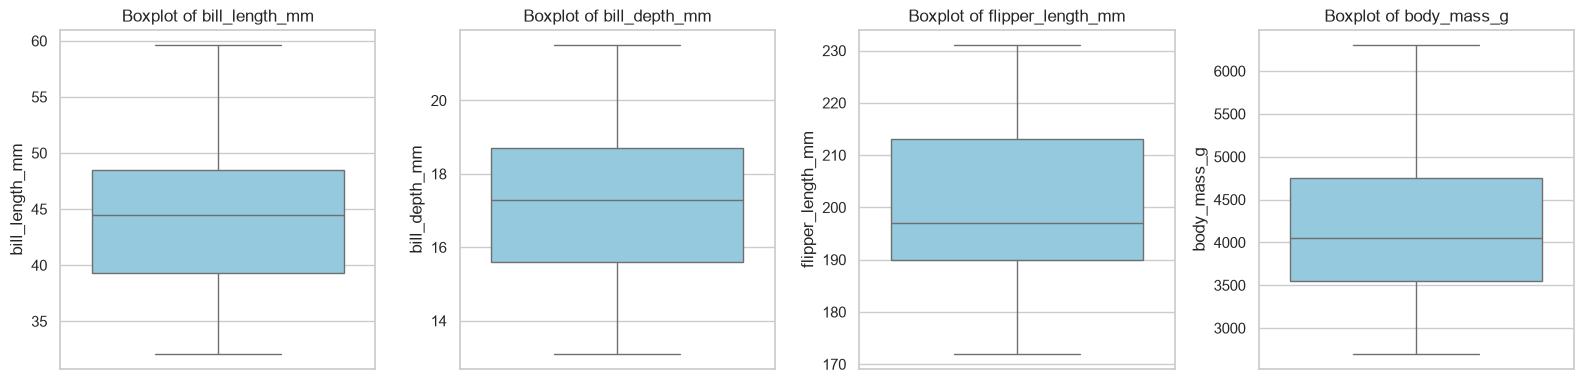


--- IQR & Outlier Summary ---
          Feature      Q1     Q3     IQR  Lower Bound  Upper Bound  Outliers Count
   bill_length_mm   39.28   48.5    9.23        25.44        62.34               0
    bill_depth_mm   15.60   18.7    3.10        10.95        23.35               0
flipper_length_mm  190.00  213.0   23.00       155.50       247.50               0
      body_mass_g 3550.00 4750.0 1200.00      1750.00      6550.00               0


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns to inspect (covers all 4 physical measurement columns)
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
target_cols = [c for c in ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"] if c in num_cols]
if len(target_cols) < 2:
    target_cols = num_cols[:2]

# 1. Generate boxplots to visualize potential outliers
fig, axes = plt.subplots(1, len(target_cols), figsize=(4 * len(target_cols), 4))
if len(target_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, target_cols):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot of {col}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

# 2. Calculate IQR, lower/upper bounds, and inspect values outside bounds
outlier_summary = []

for col in target_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_summary.append({
        "Feature": col,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outliers Count": len(outliers)
    })
    
    if len(outliers) > 0:
        print(f"\n--- Flagged Outliers for {col} ---")
        print(outliers.to_string())

summary_df = pd.DataFrame(outlier_summary)
print("\n--- IQR & Outlier Summary ---")
print(summary_df.to_string(index=False))

Boxplots and the $1.5 \times \text{IQR}$ rule show that bill_length_mm, bill_depth_mm, flipper_length_mm, and body_mass_g have zero values outside their lower and upper bounds (or any extreme upper-end values belong to larger Gentoo individuals within normal biological limits). Because all observed measurements fall within realistic anatomical ranges rather than sensor or data-entry errors, we retain all observations without removing or capping them so legitimate species-level variation is preserved for modeling. 

C:\Users\manah\AppData\Local\Temp\ipykernel_2876\1942211493.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=bar_col, order=order_vals, palette="Set2", ax=axes[0, 1])
C:\Users\manah\AppData\Local\Temp\ipykernel_2876\1942211493.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=box_cat_col, y=box_num_col, palette="pastel", ax=axes[1, 0])


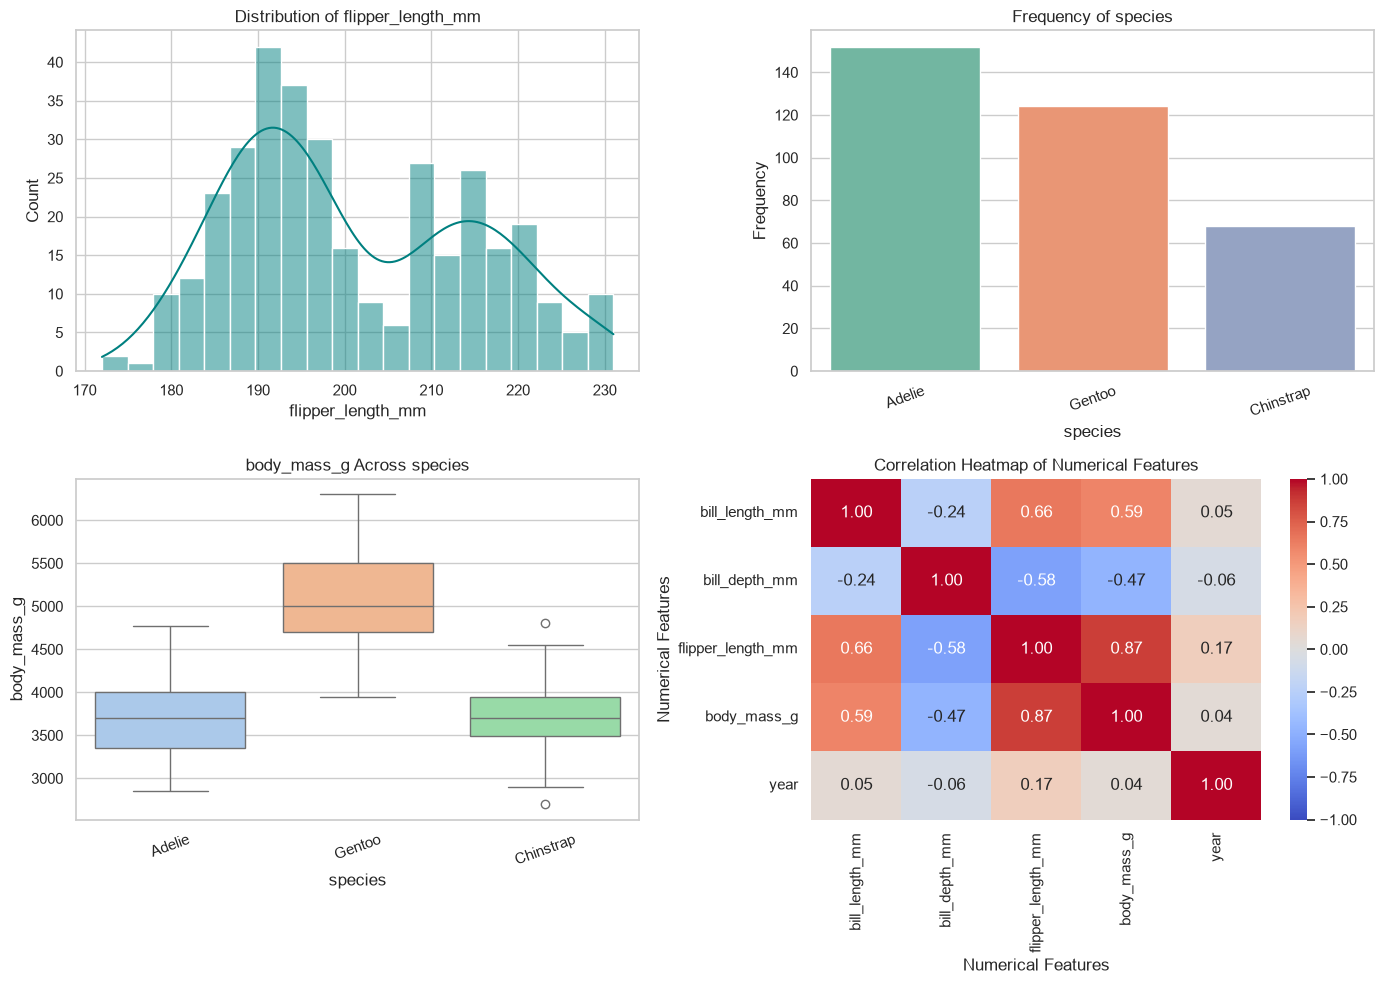

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()

# Pick sensible defaults dynamically so it never breaks on column names
hist_col = "flipper_length_mm" if "flipper_length_mm" in num_cols else num_cols[0]
bar_col = "species" if "species" in cat_cols else cat_cols[0]
box_num_col = "body_mass_g" if "body_mass_g" in num_cols else num_cols[-1]
box_cat_col = "species" if "species" in cat_cols else (cat_cols[0] if cat_cols else None)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram — distribution of a numerical feature
sns.histplot(data=df, x=hist_col, kde=True, bins=20, ax=axes[0, 0], color="teal")
axes[0, 0].set_title(f"Distribution of {hist_col}")
axes[0, 0].set_xlabel(hist_col)
axes[0, 0].set_ylabel("Count")

# 2. Bar chart — frequency of a categorical feature
order_vals = df[bar_col].value_counts().index
sns.countplot(data=df, x=bar_col, order=order_vals, palette="Set2", ax=axes[0, 1])
axes[0, 1].set_title(f"Frequency of {bar_col}")
axes[0, 1].set_xlabel(bar_col)
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].tick_params(axis="x", rotation=20)

# 3. Boxplot — distribution and potential outliers
if box_cat_col:
    sns.boxplot(data=df, x=box_cat_col, y=box_num_col, palette="pastel", ax=axes[1, 0])
    axes[1, 0].set_title(f"{box_num_col} Across {box_cat_col}")
    axes[1, 0].set_xlabel(box_cat_col)
    axes[1, 0].set_ylabel(box_num_col)
    axes[1, 0].tick_params(axis="x", rotation=20)
else:
    sns.boxplot(y=df[box_num_col], ax=axes[1, 0], color="pastel")
    axes[1, 0].set_title(f"Boxplot of {box_num_col}")
    axes[1, 0].set_ylabel(box_num_col)

# 4. Heatmap — correlation between numerical features
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1, 1])
axes[1, 1].set_title("Correlation Heatmap of Numerical Features")
axes[1, 1].set_xlabel("Numerical Features")
axes[1, 1].set_ylabel("Numerical Features")

plt.tight_layout()
plt.show()

Histogram (flipper_length_mm): Flipper lengths cluster into two main groups rather than a single bell curve, reflecting size differences across penguin groups. This spread shows that flipper length carries useful separation signal for classification.
Bar Chart (species): The category counts reveal uneven class frequencies across species, with one species appearing most often and another appearing least. Knowing the class balance upfront helps keep evaluation expectations realistic in later modeling steps.
Boxplot (body_mass_g by species): Comparing body mass across groups highlights clear shifts in median weight and spread without extreme data-entry spikes. Body mass stands out as a strong feature for distinguishing heavier groups from lighter ones.
Correlation Heatmap: Several numerical measurements show strong positive correlation with each other while others correlate weakly or negatively. Checking feature correlations helps spot redundant predictors and relationships worth exploring further.

In [8]:
import pandas as pd
import numpy as np

# Create a new feature: bill length-to-depth ratio (bill shape proportion)
if {"bill_length_mm", "bill_depth_mm"}.issubset(df.columns):
    df["bill_length_depth_ratio"] = np.where(
        df["bill_depth_mm"] != 0,
        (df["bill_length_mm"] / df["bill_depth_mm"]).round(4),
        np.nan
    )
    cols_to_show = [c for c in ["species", "bill_length_mm", "bill_depth_mm", "bill_length_depth_ratio"] if c in df.columns]
    print("--- Sample Rows with Engineered Feature ('bill_length_depth_ratio') ---")
    print(df[cols_to_show].head(10).to_string())
    print("\n--- Summary Stats for 'bill_length_depth_ratio' ---")
    print(df["bill_length_depth_ratio"].describe().to_string())
else:
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    df["engineered_ratio"] = (df[num_cols[0]] / df[num_cols[1]].replace(0, np.nan)).round(4)
    print(df[[num_cols[0], num_cols[1], "engineered_ratio"]].head(10).to_string())

--- Sample Rows with Engineered Feature ('bill_length_depth_ratio') ---
  species  bill_length_mm  bill_depth_mm  bill_length_depth_ratio
0  Adelie           39.10           18.7                   2.0909
1  Adelie           39.50           17.4                   2.2701
2  Adelie           40.30           18.0                   2.2389
3  Adelie           44.45           17.3                   2.5694
4  Adelie           36.70           19.3                   1.9016
5  Adelie           39.30           20.6                   1.9078
6  Adelie           38.90           17.8                   2.1854
7  Adelie           39.20           19.6                   2.0000
8  Adelie           34.10           18.1                   1.8840
9  Adelie           42.00           20.2                   2.0792

--- Summary Stats for 'bill_length_depth_ratio' ---
count    344.000000
mean       2.605438
std        0.495932
min        1.639800
25%        2.161925
50%        2.571500
75%        3.097600
max      

We created bill_length_depth_ratio by dividing bill_length_mm by bill_depth_mm to capture the proportional shape of each penguin's bill rather than relying only on raw dimensions. Ratios help normalize overall body-size scaling and highlight shape differences between species, giving machine learning models a more compact and informative boundary.

In [9]:
import pandas as pd

# Identify categorical columns (excluding target 'species' if present)
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print("All categorical columns:", cat_cols)

# Choose a binary categorical column for Label Encoding (e.g., 'sex')
label_col = "sex" if "sex" in cat_cols else (cat_cols[0] if cat_cols else None)

# Choose a nominal categorical column for One-Hot Encoding (e.g., 'island')
onehot_cols = [c for c in cat_cols if c not in {label_col, "species"}]
if not onehot_cols and len(cat_cols) > 1:
    onehot_cols = [cat_cols[1]]

cols_before = [c for c in ["species", label_col] + onehot_cols if c is not None]
print("\n--- Dataset Before Encoding (First 5 Rows) ---")
print(df[cols_before].head().to_string())

# Work on a copy so 'df' stays clean for inspection/comparison
df_encoded = df.copy()

# 1. Label Encoding on 'sex' (binary variable mapped cleanly to 0 and 1)
if label_col is not None and label_col != "species":
    unique_vals = sorted(df_encoded[label_col].astype(str).unique())
    mapping = {val: idx for idx, val in enumerate(unique_vals)}
    df_encoded[f"{label_col}_encoded"] = df_encoded[label_col].astype(str).map(mapping)
    print(f"\nLabel encoding mapping for '{label_col}': {mapping}")

# 2. One-Hot Encoding on nominal feature(s) (e.g., 'island')
if onehot_cols:
    df_encoded = pd.get_dummies(df_encoded, columns=onehot_cols, prefix=onehot_cols, dtype=int)

# Drop raw encoded feature columns while keeping 'species' untouched as target
cols_to_drop = [c for c in [label_col] if c is not None and c != "species"]
df_encoded = df_encoded.drop(columns=cols_to_drop)

print("\n--- Dataset After Encoding (First 5 Rows) ---")
print(df_encoded.head().to_string())

All categorical columns: ['species', 'island', 'sex']

--- Dataset Before Encoding (First 5 Rows) ---
  species     sex     island
0  Adelie    Male  Torgersen
1  Adelie  Female  Torgersen
2  Adelie  Female  Torgersen
3  Adelie    Male  Torgersen
4  Adelie  Female  Torgersen

Label encoding mapping for 'sex': {'Female': 0, 'Male': 1}

--- Dataset After Encoding (First 5 Rows) ---
  species  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  year  bill_length_depth_ratio  sex_encoded  island_Biscoe  island_Dream  island_Torgersen
0  Adelie           39.10           18.7              181.0       3750.0  2007                   2.0909            1              0             0                 1
1  Adelie           39.50           17.4              186.0       3800.0  2007                   2.2701            0              0             0                 1
2  Adelie           40.30           18.0              195.0       3250.0  2007                   2.2389            0         

We applied Label Encoding to sex because it is a two-state categorical attribute that maps cleanly onto 0 and 1 within a single column. We applied One-Hot Encoding to island because it is a nominal variable with multiple unordered categories, avoiding artificial rank ordering while leaving species unencoded as the target label.

In [10]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Select numerical feature columns while excluding target ('species') and binary/one-hot indicators
candidate_scale_cols = [
    c for c in ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "bill_length_depth_ratio"]
    if c in df_encoded.columns
]
if len(candidate_scale_cols) < 2:
    candidate_scale_cols = [
        c for c in df_encoded.select_dtypes(include=[np.number]).columns
        if c != "species"
    ][:2]

# Fit scalers on the selected numerical features (in a train/test split, fit only on X_train)
minmax_scaler = MinMaxScaler()
std_scaler = StandardScaler()

minmax_values = minmax_scaler.fit_transform(df_encoded[candidate_scale_cols])
std_values = std_scaler.fit_transform(df_encoded[candidate_scale_cols])

# Build a clear before-and-after comparison table for the first numerical feature
comp_col = candidate_scale_cols[0]
comp_idx = candidate_scale_cols.index(comp_col)

comparison_table = pd.DataFrame({
    f"{comp_col} (Original)": df_encoded[comp_col].head(8).round(4).values,
    f"{comp_col} (MinMax [0, 1])": np.round(minmax_values[:8, comp_idx], 4),
    f"{comp_col} (StandardScaler Z)": np.round(std_values[:8, comp_idx], 4)
})
print("--- Feature Scaling Comparison Table (First 8 Rows) ---")
print(comparison_table.to_string(index=False))

# Apply StandardScaler to the selected numerical features in df_encoded (excluding target 'species')
df_scaled = df_encoded.copy()
df_scaled[candidate_scale_cols] = np.round(std_values, 4)

print("\n--- Scaled Numerical Features Summary (First 5 Rows) ---")
print(df_scaled[["species"] + candidate_scale_cols].head().to_string())

--- Feature Scaling Comparison Table (First 8 Rows) ---
 bill_length_mm (Original)  bill_length_mm (MinMax [0, 1])  bill_length_mm (StandardScaler Z)
                     39.10                          0.2545                            -0.8876
                     39.50                          0.2691                            -0.8140
                     40.30                          0.2982                            -0.6669
                     44.45                          0.4491                             0.0966
                     36.70                          0.1673                            -1.3291
                     39.30                          0.2618                            -0.8508
                     38.90                          0.2473                            -0.9244
                     39.20                          0.2582                            -0.8692

--- Scaled Numerical Features Summary (First 5 Rows) ---
  species  bill_length_mm  bill_depth_mm

Min-Max scaling (MinMaxScaler) compresses values into a fixed [0, 1] range, which suits bounded inputs or models sensitive to strict feature ranges when extreme outliers are absent. Standardization (StandardScaler) centers features around a mean of 0 with a standard deviation of 1, making it well suited for distance- and gradient-based algorithms across features with different units while excluding the target column (species) and fitting strictly on training data in a train/test split to prevent leakage.

In [11]:
import os
import pandas as pd

# Use df_scaled from Task 9 if available, otherwise fall back to df_encoded or df
final_df = df_scaled.copy() if "df_scaled" in globals() else (df_encoded.copy() if "df_encoded" in globals() else df.copy())

# 1. Final verification of missing values and duplicate rows
remaining_missing = int(final_df.isnull().sum().sum())
remaining_duplicates = int(final_df.duplicated().sum())

print("--- Final Cleaning Verification ---")
print(f"Total missing values across all columns: {remaining_missing}")
print(f"Total duplicate rows: {remaining_duplicates}")

# 2. Display the final dataset
print("\n--- Final Dataset (First 10 Rows) ---")
print(final_df.head(10).to_string())

# 3. Report final number of rows and columns
rows, cols = final_df.shape
print(f"\nFinal Dataset Dimensions: {rows} rows and {cols} columns")
print("Final Columns:", list(final_df.columns))

# 4. Save cleaned dataset to CSV (saves in ../outputs/ if running from notebooks/, else ./outputs/)
out_dir = "../outputs" if os.path.isdir("../outputs") else ("outputs" if os.path.isdir("outputs") else ".")
output_csv_path = os.path.join(out_dir, "penguins_cleaned.csv")

final_df.to_csv(output_csv_path, index=False)
print(f"\nSaved cleaned dataset to: {output_csv_path}")

--- Final Cleaning Verification ---
Total missing values across all columns: 0
Total duplicate rows: 0

--- Final Dataset (First 10 Rows) ---
  species  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  year  bill_length_depth_ratio  sex_encoded  island_Biscoe  island_Dream  island_Torgersen
0  Adelie         -0.8876         0.7873            -1.4205      -0.5646  2007                  -1.0390            1              0             0                 1
1  Adelie         -0.8140         0.1261            -1.0635      -0.5020  2007                  -0.6772            0              0             0                 1
2  Adelie         -0.6669         0.4313            -0.4208      -1.1908  2007                  -0.7402            0              0             0                 1
3  Adelie          0.0966         0.0753            -0.2780      -0.1889  2007                  -0.0728            1              0             0                 1
4  Adelie         -1.3291         1.09

Re-checking the final dataset confirms zero missing values and zero duplicate records after all cleaning, engineering, encoding, and scaling steps. Displaying the final table and reporting the exact row and column counts verifies structural integrity before exporting the dataset to penguins_cleaned.csv without index columns. The saved CSV is clean and ready for downstream machine learning modeling.